strategia MEAN-REVERSION

In [42]:
#importo i pacchetti

import numpy as np
import pandas as pd
from pylab import mpl, plt



In [43]:
#Carico il dataset
raw = pd.read_csv('http://hilpisch.com/pyalgo_eikon_eod_data.csv',
                   index_col=0, parse_dates=True).dropna()
data = pd.DataFrame(raw['GDX'])


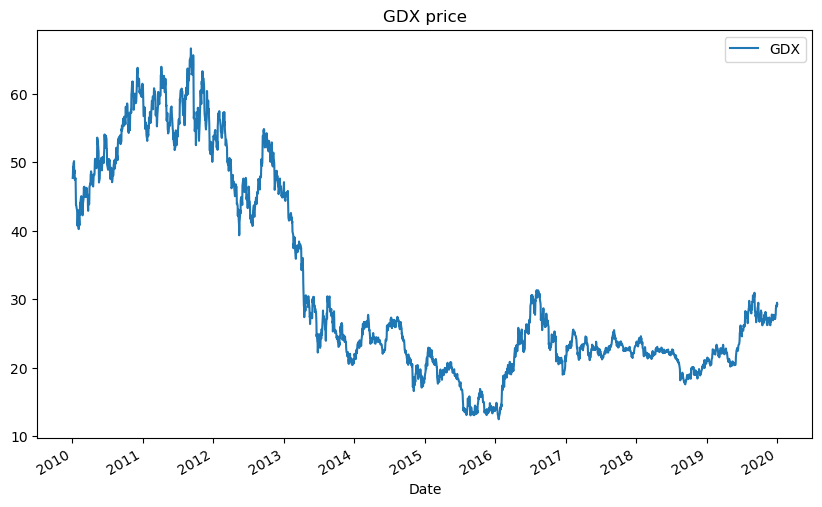

In [24]:
#plot del grafico per farci una idea

data.plot(title='GDX price',
          figsize=(10, 6));

In [44]:
#modifico il datset

data.rename(columns={'GDX': 'price'}, inplace=True)
data['returns'] = np.log(data['price'] / #colonna dei ritorni
                         data['price'].shift(1))

In [45]:
#as a mean the 25-day simple moving average is taken
#stocks are generally assumed to trend
#currencies, gold, volatiliy are normally mean-reverting
#question is always what exactly is the mean
SMA = 25
data['SMA'] = data['price'].rolling(SMA).mean() #creo la colonna sma 

In [46]:
#creo la colonna distance che calcola il valore della distanza tra la media e il prezzo attuale
data['distance'] = data['price'] - data['SMA']

In [47]:
#ora devo creare una treesholds, la voglio fare mobile e non più fissa come prima la treeshold è uguale al doppio della dev standard della finestra mobile di 25 giorni
# voglio mettere che se il movimento è maggiore del 20% allora il prezzo si inverte e tende a tornare verso la media

data['Upper Band'] =  2 * data['distance'].rolling(25).std()
data['Lower Band'] =  - 2 * data['distance'].rolling(25).std()


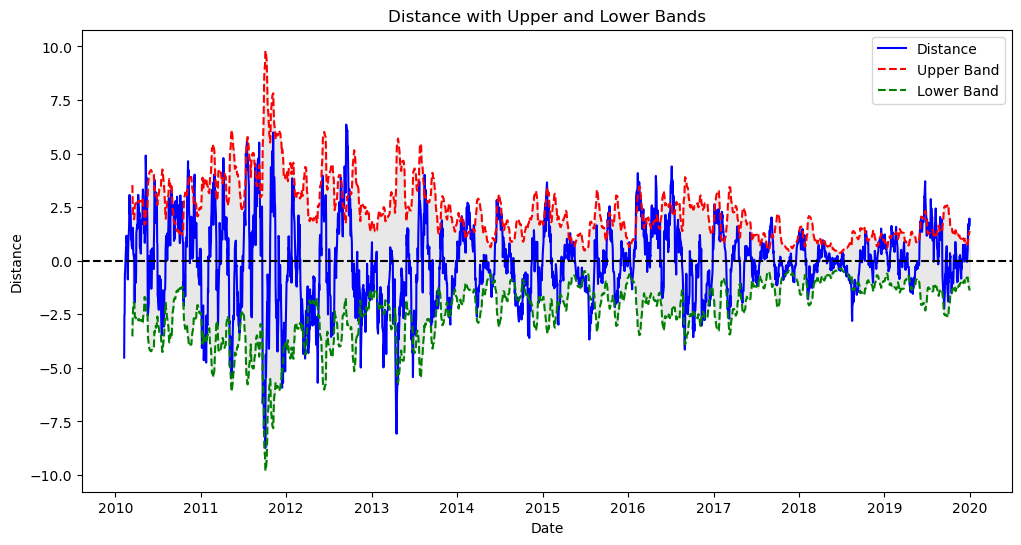

In [48]:
#ora plotto il grafico delle distnze con le thresholds

import matplotlib.pyplot as plt

# Plot della distanza con bande superiore e inferiore
plt.figure(figsize=(12, 6))
plt.plot(data['distance'], label='Distance', color='blue')
plt.plot(data['Upper Band'], label='Upper Band', linestyle='--', color='red')
plt.plot(data['Lower Band'], label='Lower Band', linestyle='--', color='green')
plt.fill_between(data.index, data['Upper Band'], data['Lower Band'], color='lightgray', alpha=0.5)
plt.axhline(0, color='black', linestyle='--')  # linea di riferimento per lo zero
plt.title('Distance with Upper and Lower Bands')
plt.xlabel('Date')
plt.ylabel('Distance')
plt.legend()
plt.show()


In [49]:
#creo la colonna position che mi dice quando comprare e quando vendere
#when the distance, i.e. the price, is above the upper band we would go short with the expectation that the price will return to the mean
data['position'] = np.where(data['distance'] > data['Upper Band'],
                            -1, np.nan)

#when the distance, i.e. the price, is below the lower threshold we would go long with the expectation that the price will return to the mean
data['position'] = np.where(data['distance'] < data['Lower Band'],
                            1, data['position'])

In [50]:
#lo 0 può essere il nostro segnale di stop, non puntiamo ad arrivare all'altra banda ma alla media, pk sappiamo che nel lungo termine il prezzo tenderà a tornare alla media

#Contrary to the other two strategies we are also neutral in this strategy, i.e. we can be long, short or neutral. The question is when are we neutral?
#When the 'distance' changes from negative to positive or from positive to negative we put in a 0, i.e. we become neutral
#so: whenever there is a change in the sign from + to - or from -to +
data['position'] = np.where(data['distance'] *
           data['distance'].shift(1) < 0, 0, data['position'])

In [51]:
#positions are still not filled up to the neutrals which we take care of here
#for filling up the positions till there is trade signal we use forward fill, i.e. the ffill() method since we stay long till there is a change in the sign of distance
#This method fills any remaining missing values with 0. It replaces any remaining NaNs with the specified value of 0.
data['position'] = data['position'].ffill().fillna(0)

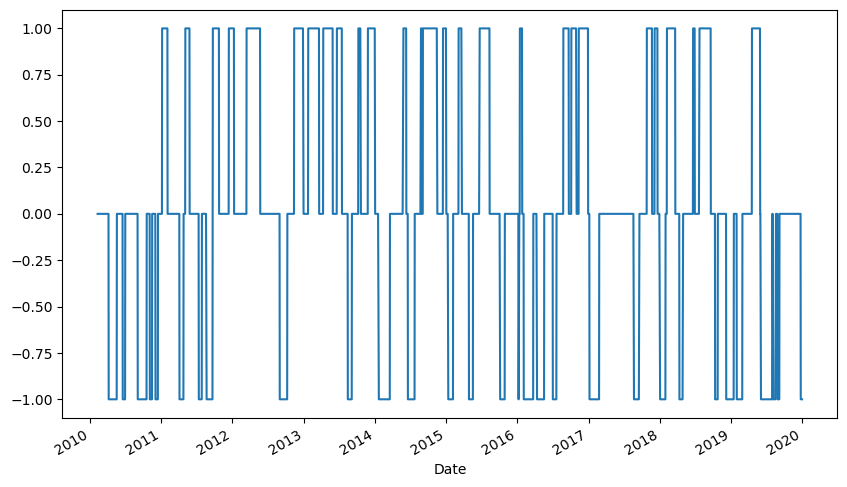

In [52]:
#This is how the strategy looks like in terms of +1, 0 and -1
#what we see here is that we have long stretches of being market neutral, i.e. without being neither long nor short, because neither the upper nor the lower threshold was hit
data['position'].iloc[SMA:].plot(ylim=[-1.1, 1.1],
                               figsize=(10, 6));

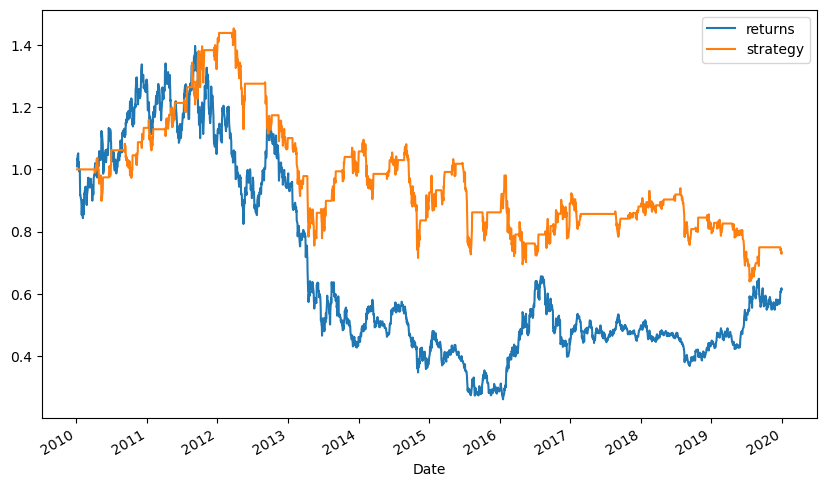

In [53]:
#Now i'm backtesting the strategy 
#note that5 we use the same dataset so it's not so accurate
#we can change dataset to test again

data['strategy'] = data['position'].shift(1) * data['returns']
data[['returns', 'strategy']].dropna().cumsum(
        ).apply(np.exp).plot(figsize=(10, 6));